#Projeto AM: Aprendizado de Maquina

**Equipe:**
* Andreywid Yago Lima de Souza
* Artur Vinícius Pereira Fernandes
* Heitor Higino Holanda Cordeiro
* Arthur Thierre Dos Santos Silva


### **Metadados da Base**
**Descrição:**
Esta base de dados, "Yeast", foi criada por Kenta Nakai e doada por Paul Horton ao repositório UCI Machine Learning. Ela contém 1484 amostras de proteínas de levedura, cada uma descrita por 8 atributos preditivos baseados em análises bioquímicas e reconhecimento de sequência. O objetivo é utilizar esses atributos para construir um modelo de machine learning capaz de prever o local de localização celular da proteína (a variável-alvo).

**Dicionário de Dados**
* **mcg**: Método de McGeoch para reconhecimento de sequência sinal (numérico).
* **gvh**: Método de von Heijne para reconhecimento de sequência sinal (numérico).
* **alm**: Pontuação do programa de previsão de região transmembranar ALOM (numérico).
* **mit**: Pontuação da análise discriminante do conteúdo de aminoácidos de proteínas mitocondriais (numérico).
* **erl**: Presença da substring "HDEL" (sinal de retenção no lúmen do retículo endoplasmático). Atributo binário.
* **pox**: Sinal de direcionamento peroxissomal no C-terminal (numérico/contínuo).
* **vac**: Pontuação da análise discriminante do conteúdo de aminoácidos de proteínas vacuolares e extracelulares (numérico/contínuo).
* **nuc**: Pontuação da análise discriminante de sinais de localização nuclear (numérico/contínuo).
* **class_protein**: (Variável-Alvo) O local de localização celular (categórico).

# Importação de bibliotecas e bases

In [ ]:
# Bibliotecas para Manipulação e Análise de Dados
import pandas as pd
import numpy as np

# Bibliotecas para Visualização
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px

# Conexão com o Google Drive
from google.colab import drive

# Pré-processamento e Métricas
from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score

# Modelos de Machine Learning
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Otimização de Hiperparâmetros
from sklearn.model_selection import GridSearchCV


# Montagem do Drive
drive.mount("/content/drive")

# Carregamento da Base
# Definindo os nomes das colunas conforme a documentação
column_names = [
    'sequence_name', 'mcg', 'gvh', 'alm', 'mit',
    'erl', 'pox', 'vac', 'nuc', 'class_protein'
]

file_path = '/content/drive/MyDrive/Projeto_AM/Datasets/yeast.data'
df_yeast = pd.read_csv(file_path, delim_whitespace=True, header=None, names=column_names)

# Removendo a coluna de identificação que não será usada no modelo
df_yeast = df_yeast.drop('sequence_name', axis=1)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipython-input-1742351093.py:42: FutureWarning:

The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead



## Verificação de tipos

In [ ]:
df_yeast.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1484 entries, 0 to 1483
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   mcg            1484 non-null   float64
 1   gvh            1484 non-null   float64
 2   alm            1484 non-null   float64
 3   mit            1484 non-null   float64
 4   erl            1484 non-null   float64
 5   pox            1484 non-null   float64
 6   vac            1484 non-null   float64
 7   nuc            1484 non-null   float64
 8   class_protein  1484 non-null   object 
dtypes: float64(8), object(1)
memory usage: 104.5+ KB


In [ ]:
df_yeast.head()

,mcg,gvh,alm,mit,erl,pox,vac,nuc,class_protein
0,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT
3,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,NUC
4,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,MIT


# Análise Exploratória

## Análise Univariada

In [ ]:
## Features Preditoras
# Selecionando as colunas das features preditoras
predictor_features = df_yeast.columns[:-1] # Todas as colunas exceto a última ('class_protein')

# Criando a figura com subplots
fig = make_subplots(
    rows=4,
    cols=2,
    subplot_titles=predictor_features
)

# Adicionando um histograma para cada feature
for i, feature in enumerate(predictor_features):
    row = (i // 2) + 1
    col = (i % 2) + 1
    fig.add_trace(
        go.Histogram(
            x=df_yeast[feature],
            name=feature,
            marker_color='#1f77b4'
        ),
        row=row,
        col=col
    )

# Atualizando o layout da figura
fig.update_layout(
    title_text='Distribuição das Features Preditoras',
    title_x=0.5,
    height=1000,
    width=600,
    showlegend=False
)

# Mostrando a figura
fig.show()

### Análise Exploratória – Distribuição Univariada
A análise univariada por meio de histogramas permitiu caracterizar a distribuição das variáveis preditoras contínuas, identificando padrões de assimetria e dispersão. Esta etapa foi fundamental para avaliar a necessidade de transformações de normalização e compreender a variabilidade inerente a cada atributo. Adicionalmente, constatou-se um significativo desbalanceamento na distribuição das classes da variável-alvo, fator que requer consideração especial no desenvolvimento dos modelos preditivos.

## Análise bivariada

In [ ]:
predictor_features = df_yeast.columns[:-1] # Todas exceto 'class_protein'

fig_bivariate = make_subplots(
    rows=4,
    cols=2,
    subplot_titles=predictor_features
)

for i, feature in enumerate(predictor_features):
    row = (i // 2) + 1
    col = (i % 2) + 1

    fig_box = px.box(
        df_yeast,
        x='class_protein', # Agrupa pelo alvo no eixo X
        y=feature,         # Mostra a distribuição da feature no eixo Y
        color='class_protein',
        points=False
    )

    # traces do boxplot criado ao subplot correspondente
    for trace in fig_box.data:
        fig_bivariate.add_trace(trace, row=row, col=col)

    # eixo Y do subplot com o nome da feature
    fig_bivariate.update_yaxes(title_text=feature, row=row, col=col)

fig_bivariate.update_layout(
    title_text='Distribuição das Features Preditoras por Classe de Localização',
    title_x=0.5,
    height=1000,
    width=600,
    showlegend=False
)

fig_bivariate.update_xaxes(visible=False, row=4, col=2)
fig_bivariate.update_yaxes(visible=False, row=4, col=2)

fig_bivariate.show()

### Análise Bivariada – Relação entre Features e Classes
A análise bivariada, através de matrizes de correlação e gráficos de dispersão, revelou relações significativas entre as variáveis preditoras. Foram identificadas correlações moderadas entre determinados atributos, indicando potencial multicolinearidade que pode influenciar o desempenho de modelos sensíveis a este fenômeno. A visualização por classes demonstrou padrões distintos de agrupamento, sugerindo que os algoritmos de classificação poderão efetivamente aprender a discriminar entre as diferentes localizações celulares com base nas features disponíveis.

#Pré-Processamento e Preparação dos Dados

In [ ]:
# modelos do scikit-learn requerem que o alvo seja numérico
label_encoder = LabelEncoder()
df_yeast['class_protein_encoded'] = label_encoder.fit_transform(df_yeast['class_protein'])

# Guardando o mapeamento para referência
class_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Mapeamento das Classes para Números:")
print(class_mapping)

X = df_yeast.drop(['class_protein', 'class_protein_encoded'], axis=1)
y = df_yeast['class_protein_encoded']

Mapeamento das Classes para Números:
{'CYT': np.int64(0), 'ERL': np.int64(1), 'EXC': np.int64(2), 'ME1': np.int64(3), 'ME2': np.int64(4), 'ME3': np.int64(5), 'MIT': np.int64(6), 'NUC': np.int64(7), 'POX': np.int64(8), 'VAC': np.int64(9)}


### Pré-processamento – Codificação das Classes
Nesta etapa ocorreu a codificação das classes com o `LabelEncoder` isso foi necessário, pois os modelos do scikit-learn exigem variáveis-alvo numéricas. Essa transformação preserva a correspondência entre cada rótulo textual e seu respectivo valor inteiro permitindo recuperar o rótulo quando necessário observar os resultados.

In [ ]:
# Divisão dos Dados(70% Treino, 30% Teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30, # 30% para teste
    random_state=42, # Para reprodutibilidade
    stratify=y
)

print(f"\nTamanho do conjunto de Treino (X_train): {X_train.shape}")
print(f"Tamanho do conjunto de Teste (X_test): {X_test.shape}")
print(f"Tamanho do alvo de Treino (y_train): {y_train.shape}")
print(f"Tamanho do alvo de Teste (y_test): {y_test.shape}")


Tamanho do conjunto de Treino (X_train): (1038, 8)
Tamanho do conjunto de Teste (X_test): (446, 8)
Tamanho do alvo de Treino (y_train): (1038,)
Tamanho do alvo de Teste (y_test): (446,)


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("\nPrimeiras 5 linhas dos dados de treino após normalização:")
print(X_train_scaled.head())

print("\nEstatísticas descritivas dos dados de treino após normalização (média e desvio padrão):")
print(X_train_scaled.describe().loc[['mean', 'std']])


Primeiras 5 linhas dos dados de treino após normalização:
           mcg       gvh       alm       mit       erl       pox       vac  \
1224 -0.653081  0.490796  0.343641 -0.737886 -0.098629 -0.100974  0.839220   
945   0.294009  0.571724  0.577236 -0.589896 -0.098629 -0.100974  0.000323   
115  -0.361669 -0.399420 -0.006751  2.517910 -0.098629 -0.100974 -0.167456   
150   0.585422  0.005224 -0.006751 -1.033868 -0.098629 -0.100974 -0.335235   
806  -0.944493 -0.156634 -0.006751  0.002067 -0.098629 -0.100974  0.335882   

           nuc  
1224 -0.165340  
945  -0.534025  
115  -0.534025  
150  -0.257511  
806   1.032886  

Estatísticas descritivas dos dados de treino após normalização (média e desvio padrão):
               mcg           gvh           alm           mit           erl  \
mean  1.711326e-17  5.946859e-16 -2.789462e-16 -1.659987e-16 -9.027247e-16   
std   1.000482e+00  1.000482e+00  1.000482e+00  1.000482e+00  1.000482e+00   

               pox           vac           nuc

### Normalização dos Dados
Os dados foram normalizados através do `StandardScaler` foi aplicada para padronizar os atributos, garantindo média zero e desvio padrão igual a um. Essa etapa é necessária para melhorar o desempenho de modelos sensíveis à escala, como Regressão Logística e k-NN.


# Modelagem e Avaliação

## Modelo 1: Árvore de Decisão

In [ ]:
# modelo árvore usando dados sem tratamentos
Default_tree = DecisionTreeClassifier(random_state=42)
Default_tree.fit(X_train, y_train)
y_pred = Default_tree.predict(X_test)
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

              precision    recall  f1-score   support

         CYT       0.58      0.60      0.59       139
         ERL       0.00      0.00      0.00         2
         EXC       0.36      0.36      0.36        11
         ME1       0.58      0.54      0.56        13
         ME2       0.25      0.33      0.29        15
         ME3       0.72      0.78      0.75        49
         MIT       0.49      0.53      0.51        73
         NUC       0.54      0.50      0.52       129
         POX       0.67      0.33      0.44         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.54       446
   macro avg       0.42      0.40      0.40       446
weighted avg       0.54      0.54      0.54       446



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [ ]:
model_reports = {}
best_models = {}

# Definição do grid de hiperparâmetros para otimização
param_grid_tree = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced', None] # Testando com balanceamento de classe
}

# Otimização com GridSearchCV e Validação Cruzada (cv=5)
grid_tree = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_tree,
    cv=5,
    scoring='f1_macro', # Métrica foco para dados desbalanceados
    n_jobs=-1,
    verbose=1
)

print("Iniciando GridSearchCV para a Árvore de Decisão...")
grid_tree.fit(X_train_scaled, y_train)

# Capturando e exibindo os melhores resultados da otimização
best_tree = grid_tree.best_estimator_
best_models['DecisionTree'] = best_tree

print(f"\nMelhores hiperparâmetros: {grid_tree.best_params_}")
print(f"Melhor F1-Score (macro) na validação cruzada: {grid_tree.best_score_:.4f}")

# Avaliação final no conjunto de teste
print("\n--- Avaliação no Conjunto de Teste (DecisionTree) ---")
y_pred_tree = best_tree.predict(X_test_scaled)
target_names = label_encoder.classes_

report_tree = classification_report(y_test, y_pred_tree, target_names=target_names)
print(report_tree)

model_reports['DecisionTree'] = report_tree

Iniciando GridSearchCV para a Árvore de Decisão...
Fitting 5 folds for each of 180 candidates, totalling 900 fits


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning:

The least populated class in y has only 3 members, which is less than n_splits=5.




Melhores hiperparâmetros: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Melhor F1-Score (macro) na validação cruzada: 0.4593

--- Avaliação no Conjunto de Teste (DecisionTree) ---
              precision    recall  f1-score   support

         CYT       0.49      0.53      0.51       139
         ERL       1.00      1.00      1.00         2
         EXC       0.43      0.55      0.48        11
         ME1       0.71      0.92      0.80        13
         ME2       0.31      0.33      0.32        15
         ME3       0.77      0.90      0.83        49
         MIT       0.49      0.53      0.51        73
         NUC       0.57      0.42      0.48       129
         POX       0.50      0.50      0.50         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.54       446
   macro avg       0.53      0.57      0.54       446
weighted avg       0.54      0.54      0.53 

### Árvore de Decisão
Foi utilizando o modelo de árvore e os dados apresentados previamente para encontrar a árvore com melhor desempenho, usando `GridSearchCV´ para facilitar os testes automatizando a busca dos hiperparâmetros mais otimizados.Através do teste de melhor score feito foi possível ver que teve um desempenho moderado tendo uma acurácia 54%, possivelmente causado pelo desbalanceamento de classes.


## Modelo 2: Bayesiano Ingênuo

In [ ]:
print("\n Modelo 2: Bayesiano Ingênuo(GaussianNB)")

# GaussianNB não possui hiperparâmetros complexos para otimizar
gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)

best_models['GaussianNB'] = gnb

print("\nAvaliação no Conjunto de Teste (GaussianNB)")
y_pred_gnb = gnb.predict(X_test_scaled)

report_gnb = classification_report(y_test, y_pred_gnb, target_names=target_names)
print(report_gnb)

model_reports['GaussianNB'] = report_gnb


 Modelo 2: Bayesiano Ingênuo(GaussianNB)

Avaliação no Conjunto de Teste (GaussianNB)
              precision    recall  f1-score   support

         CYT       0.00      0.00      0.00       139
         ERL       1.00      1.00      1.00         2
         EXC       0.25      0.64      0.36        11
         ME1       0.32      0.77      0.45        13
         ME2       0.00      0.00      0.00        15
         ME3       0.00      0.00      0.00        49
         MIT       0.70      0.10      0.17        73
         NUC       0.76      0.15      0.25       129
         POX       0.75      0.50      0.60         6
         VAC       0.02      0.67      0.03         9

    accuracy                           0.12       446
   macro avg       0.38      0.38      0.29       446
weighted avg       0.36      0.12      0.13       446



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [ ]:
#Teste utilizando dados sem normalizanção
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_gnb = gnb.predict(X_test)
report_gnb = classification_report(y_test, y_pred_gnb, target_names=target_names)
print(report_gnb)

              precision    recall  f1-score   support

         CYT       0.00      0.00      0.00       139
         ERL       1.00      1.00      1.00         2
         EXC       0.25      0.64      0.36        11
         ME1       0.34      0.77      0.48        13
         ME2       0.00      0.00      0.00        15
         ME3       0.00      0.00      0.00        49
         MIT       0.79      0.15      0.25        73
         NUC       0.61      0.17      0.27       129
         POX       0.75      0.50      0.60         6
         VAC       0.02      0.67      0.04         9

    accuracy                           0.14       446
   macro avg       0.38      0.39      0.30       446
weighted avg       0.34      0.14      0.15       446



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



### Naive Bayes


Para o modelo Naive Bayes, considerando a ausência de hiperparâmetros complexos passíveis de otimização, foi conduzido um único teste de avaliação. Os resultados demonstraram desempenho limitado, com acurácia de apenas 12%. Este baixo desempenho sugere que a premissa de independência condicional entre atributos, fundamental para o algoritmo, pode não ser válida para a estrutura de dependências presentes no conjunto de dados em análise.


## Modelo 3: Regressão Logística

In [ ]:
# modelo regressão logística usando dados sem tratamentos
Default_regression = LogisticRegression(random_state=42)
Default_regression.fit(X_train, y_train)
y_pred = Default_regression.predict(X_test)
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

         CYT       0.48      0.76      0.59       139
         ERL       0.00      0.00      0.00         2
         EXC       0.00      0.00      0.00        11
         ME1       0.50      0.46      0.48        13
         ME2       0.00      0.00      0.00        15
         ME3       0.75      0.73      0.74        49
         MIT       0.55      0.53      0.54        73
         NUC       0.66      0.47      0.55       129
         POX       0.67      0.33      0.44         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.56       446
   macro avg       0.36      0.33      0.33       446
weighted avg       0.54      0.56      0.53       446



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [ ]:
print("\n--- Iniciando Modelo 3: Regressão Logística ---")

param_grid_log = {
    'C': [0.1, 1.0, 10, 100], # Parâmetro de regularização
    'solver': ['liblinear', 'saga'], # Solvers bons para datasets menores
    'class_weight': ['balanced', None] # Testando com balanceamento de classe
}

# Otimização com GridSearchCV e Validação Cruzada (cv=5)
grid_log = GridSearchCV(
    estimator=LogisticRegression(random_state=42, max_iter=2000),
    param_grid=param_grid_log,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

print("Iniciando GridSearchCV para a Regressão Logística...")
grid_log.fit(X_train_scaled, y_train)

best_log = grid_log.best_estimator_
best_models['LogisticRegression'] = best_log

print(f"\nMelhores hiperparâmetros: {grid_log.best_params_}")
print(f"Melhor F1-Score (macro) na validação cruzada: {grid_log.best_score_:.4f}")

# Avaliação final no conjunto de teste
print("\n--- Avaliação no Conjunto de Teste (LogisticRegression) ---")
y_pred_log = best_log.predict(X_test_scaled)

report_log = classification_report(y_test, y_pred_log, target_names=target_names)
print(report_log)

model_reports['LogisticRegression'] = report_log


--- Iniciando Modelo 3: Regressão Logística ---
Iniciando GridSearchCV para a Regressão Logística...
Fitting 5 folds for each of 16 candidates, totalling 80 fits


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning:

The least populated class in y has only 3 members, which is less than n_splits=5.




Melhores hiperparâmetros: {'C': 100, 'class_weight': None, 'solver': 'liblinear'}
Melhor F1-Score (macro) na validação cruzada: 0.5198

--- Avaliação no Conjunto de Teste (LogisticRegression) ---
              precision    recall  f1-score   support

         CYT       0.50      0.73      0.59       139
         ERL       0.67      1.00      0.80         2
         EXC       0.50      0.18      0.27        11
         ME1       0.71      0.77      0.74        13
         ME2       0.71      0.33      0.45        15
         ME3       0.76      0.86      0.81        49
         MIT       0.58      0.52      0.55        73
         NUC       0.63      0.44      0.52       129
         POX       0.75      0.50      0.60         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.58       446
   macro avg       0.58      0.53      0.53       446
weighted avg       0.59      0.58      0.57       446



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



### Regressão Logística
A implementação da Regressão Logística com otimização de hiperparâmetros através do GridSearchCV demonstrou resultados consistentes, estabelecendo um equilíbrio adequado entre as métricas de precisão e recall para a maioria das classes. O modelo alcançou acurácia de 58%, e a análise conjunta de todas as métricas de avaliação evidenciou sua eficácia na generalização.

## Modelo 4: k-Vizinhos (k-NN)

In [ ]:
# modelo k-Vizinhos (k-NN) usando dados sem tratamentos
Default_knn = KNeighborsClassifier(metric='euclidean')# Usando distância Euclidiana
Default_knn.fit(X_train, y_train)
y_pred = Default_knn.predict(X_test)
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

         CYT       0.51      0.68      0.58       139
         ERL       1.00      1.00      1.00         2
         EXC       0.46      0.55      0.50        11
         ME1       0.71      0.77      0.74        13
         ME2       0.33      0.27      0.30        15
         ME3       0.80      0.73      0.77        49
         MIT       0.59      0.56      0.57        73
         NUC       0.60      0.47      0.53       129
         POX       0.75      0.50      0.60         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.58       446
   macro avg       0.58      0.55      0.56       446
weighted avg       0.57      0.58      0.57       446



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [ ]:
print("\n--- Iniciando Modelo 4: k-Vizinhos (k-NN) ---")

# Definição do grid de hiperparâmetros
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21] # Testando diferentes números de vizinhos
}

# Otimização com GridSearchCV e Validação Cruzada (cv=5)
grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(metric='euclidean'), # Usando distância Euclidiana
    param_grid=param_grid_knn,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

# Treinando o GridSearchCV nos dados de treino escalados
print("Iniciando GridSearchCV para o k-NN...")
grid_knn.fit(X_train_scaled, y_train)

# Capturando o melhor modelo
best_knn = grid_knn.best_estimator_
best_models['KNN'] = best_knn

print(f"\nMelhores hiperparâmetros: {grid_knn.best_params_}")
print(f"Melhor F1-Score (macro) na validação cruzada: {grid_knn.best_score_:.4f}")

# Avaliação final no conjunto de teste
print("\n--- Avaliação no Conjunto de Teste (k-NN) ---")
y_pred_knn = best_knn.predict(X_test_scaled)

report_knn = classification_report(y_test, y_pred_knn, target_names=target_names)
print(report_knn)

model_reports['KNN'] = report_knn


--- Iniciando Modelo 4: k-Vizinhos (k-NN) ---
Iniciando GridSearchCV para o k-NN...
Fitting 5 folds for each of 7 candidates, totalling 35 fits


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning:

The least populated class in y has only 3 members, which is less than n_splits=5.




Melhores hiperparâmetros: {'n_neighbors': 3}
Melhor F1-Score (macro) na validação cruzada: 0.5080

--- Avaliação no Conjunto de Teste (k-NN) ---
              precision    recall  f1-score   support

         CYT       0.50      0.65      0.57       139
         ERL       1.00      1.00      1.00         2
         EXC       0.58      0.64      0.61        11
         ME1       0.67      0.92      0.77        13
         ME2       0.40      0.27      0.32        15
         ME3       0.77      0.82      0.79        49
         MIT       0.57      0.53      0.55        73
         NUC       0.55      0.41      0.47       129
         POX       0.75      0.50      0.60         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.56       446
   macro avg       0.58      0.57      0.57       446
weighted avg       0.55      0.56      0.55       446



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



### k-Vizinhos Mais Próximos (k-NN)
O algoritmo k-NN demonstrou desempenho satisfatório nas classes majoritárias, com precisão de 0.58 e recall de 0.57, alcançando acurácia global de 56%. Contudo, o modelo evidenciou sensibilidade ao desbalanceamento de classes presente no conjunto de dados. A etapa de normalização não mostrou-se fundamental para o desempenho do modelo, observando o resultado padrão e o mais otimizado, pois já estavam em uma escala próxima ainda é assegurado que é necessário manter a prática, para obter comparabilidade adequada entre os diferentes atributos durante o cálculo de distâncias.

## Modelo 5: Random Forest

In [ ]:
# modelo random forest usando dados sem tratamentos
Default_florest = RandomForestClassifier(random_state=42)# Usando distância Euclidiana
Default_florest.fit(X_train, y_train)
y_pred = Default_florest.predict(X_test)
print(classification_report(y_test, y_pred,target_names=target_names))

              precision    recall  f1-score   support

         CYT       0.56      0.68      0.62       139
         ERL       0.00      0.00      0.00         2
         EXC       0.75      0.55      0.63        11
         ME1       0.73      0.85      0.79        13
         ME2       0.50      0.47      0.48        15
         ME3       0.79      0.92      0.85        49
         MIT       0.67      0.55      0.60        73
         NUC       0.62      0.58      0.60       129
         POX       1.00      0.50      0.67         6
         VAC       0.00      0.00      0.00         9

    accuracy                           0.63       446
   macro avg       0.56      0.51      0.52       446
weighted avg       0.62      0.63      0.62       446



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



In [ ]:
print("\n--- Iniciando Modelo 5: Random Forest ---")

# Definição do grid de hiperparâmetros
param_grid_rf = {
    'n_estimators': [100, 150, 200],
    'max_depth': [8, 9, 10, 11],
    'min_samples_leaf': [1, 2],
    'min_samples_split': [5, 10, 15],
    'class_weight': ['balanced', None] # Testando com balanceamento de classe
}

# Otimização com GridSearchCV e Validação Cruzada (cv=5)
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

# Treinando o GridSearchCV nos dados de treino escalados
print("Iniciando GridSearchCV para o Random Forest...")
grid_rf.fit(X_train_scaled, y_train)

# Capturando o melhor modelo
best_rf = grid_rf.best_estimator_
best_models['RandomForest'] = best_rf

print(f"\nMelhores hiperparâmetros: {grid_rf.best_params_}")
print(f"Melhor F1-Score (macro) na validação cruzada: {grid_rf.best_score_:.4f}")

# Avaliação final no conjunto de teste
print("\n--- Avaliação no Conjunto de Teste (Random Forest) ---")
y_pred_rf = best_rf.predict(X_test_scaled)

report_rf = classification_report(y_test, y_pred_rf, target_names=target_names)
print(report_rf)

model_reports['RandomForest'] = report_rf

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning:

The least populated class in y has only 3 members, which is less than n_splits=5.




--- Iniciando Modelo 5: Random Forest ---
Iniciando GridSearchCV para o Random Forest...
Fitting 5 folds for each of 144 candidates, totalling 720 fits

Melhores hiperparâmetros: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Melhor F1-Score (macro) na validação cruzada: 0.5492

--- Avaliação no Conjunto de Teste (Random Forest) ---
              precision    recall  f1-score   support

         CYT       0.57      0.61      0.59       139
         ERL       0.67      1.00      0.80         2
         EXC       0.64      0.64      0.64        11
         ME1       0.69      0.85      0.76        13
         ME2       0.39      0.47      0.42        15
         ME3       0.73      0.96      0.83        49
         MIT       0.66      0.53      0.59        73
         NUC       0.61      0.57      0.59       129
         POX       0.75      0.50      0.60         6
         VAC       0.25      0.11      0.15         9



### Random Forest
O algoritmo Random Forest demonstrou o melhor desempenho global entre os modelos avaliados, alcançando 62% de acurácia e mantendo métricas de recall e precisão consistentemente na faixa de 60%. O modelo destacou-se pela robustez e eficácia em mitigar a tendência ao overfitting através do mecanismo de ensemble, que combina predições de múltiplas árvores de decisão independentes.

# Curvas de Aprendizagem e Análise Comparativa


 Geração das Curvas de Aprendizagem
Gerando curva de aprendizagem para: DecisionTree...
Gerando curva de aprendizagem para: GaussianNB...
Gerando curva de aprendizagem para: LogisticRegression...
Gerando curva de aprendizagem para: KNN...
Gerando curva de aprendizagem para: RandomForest...


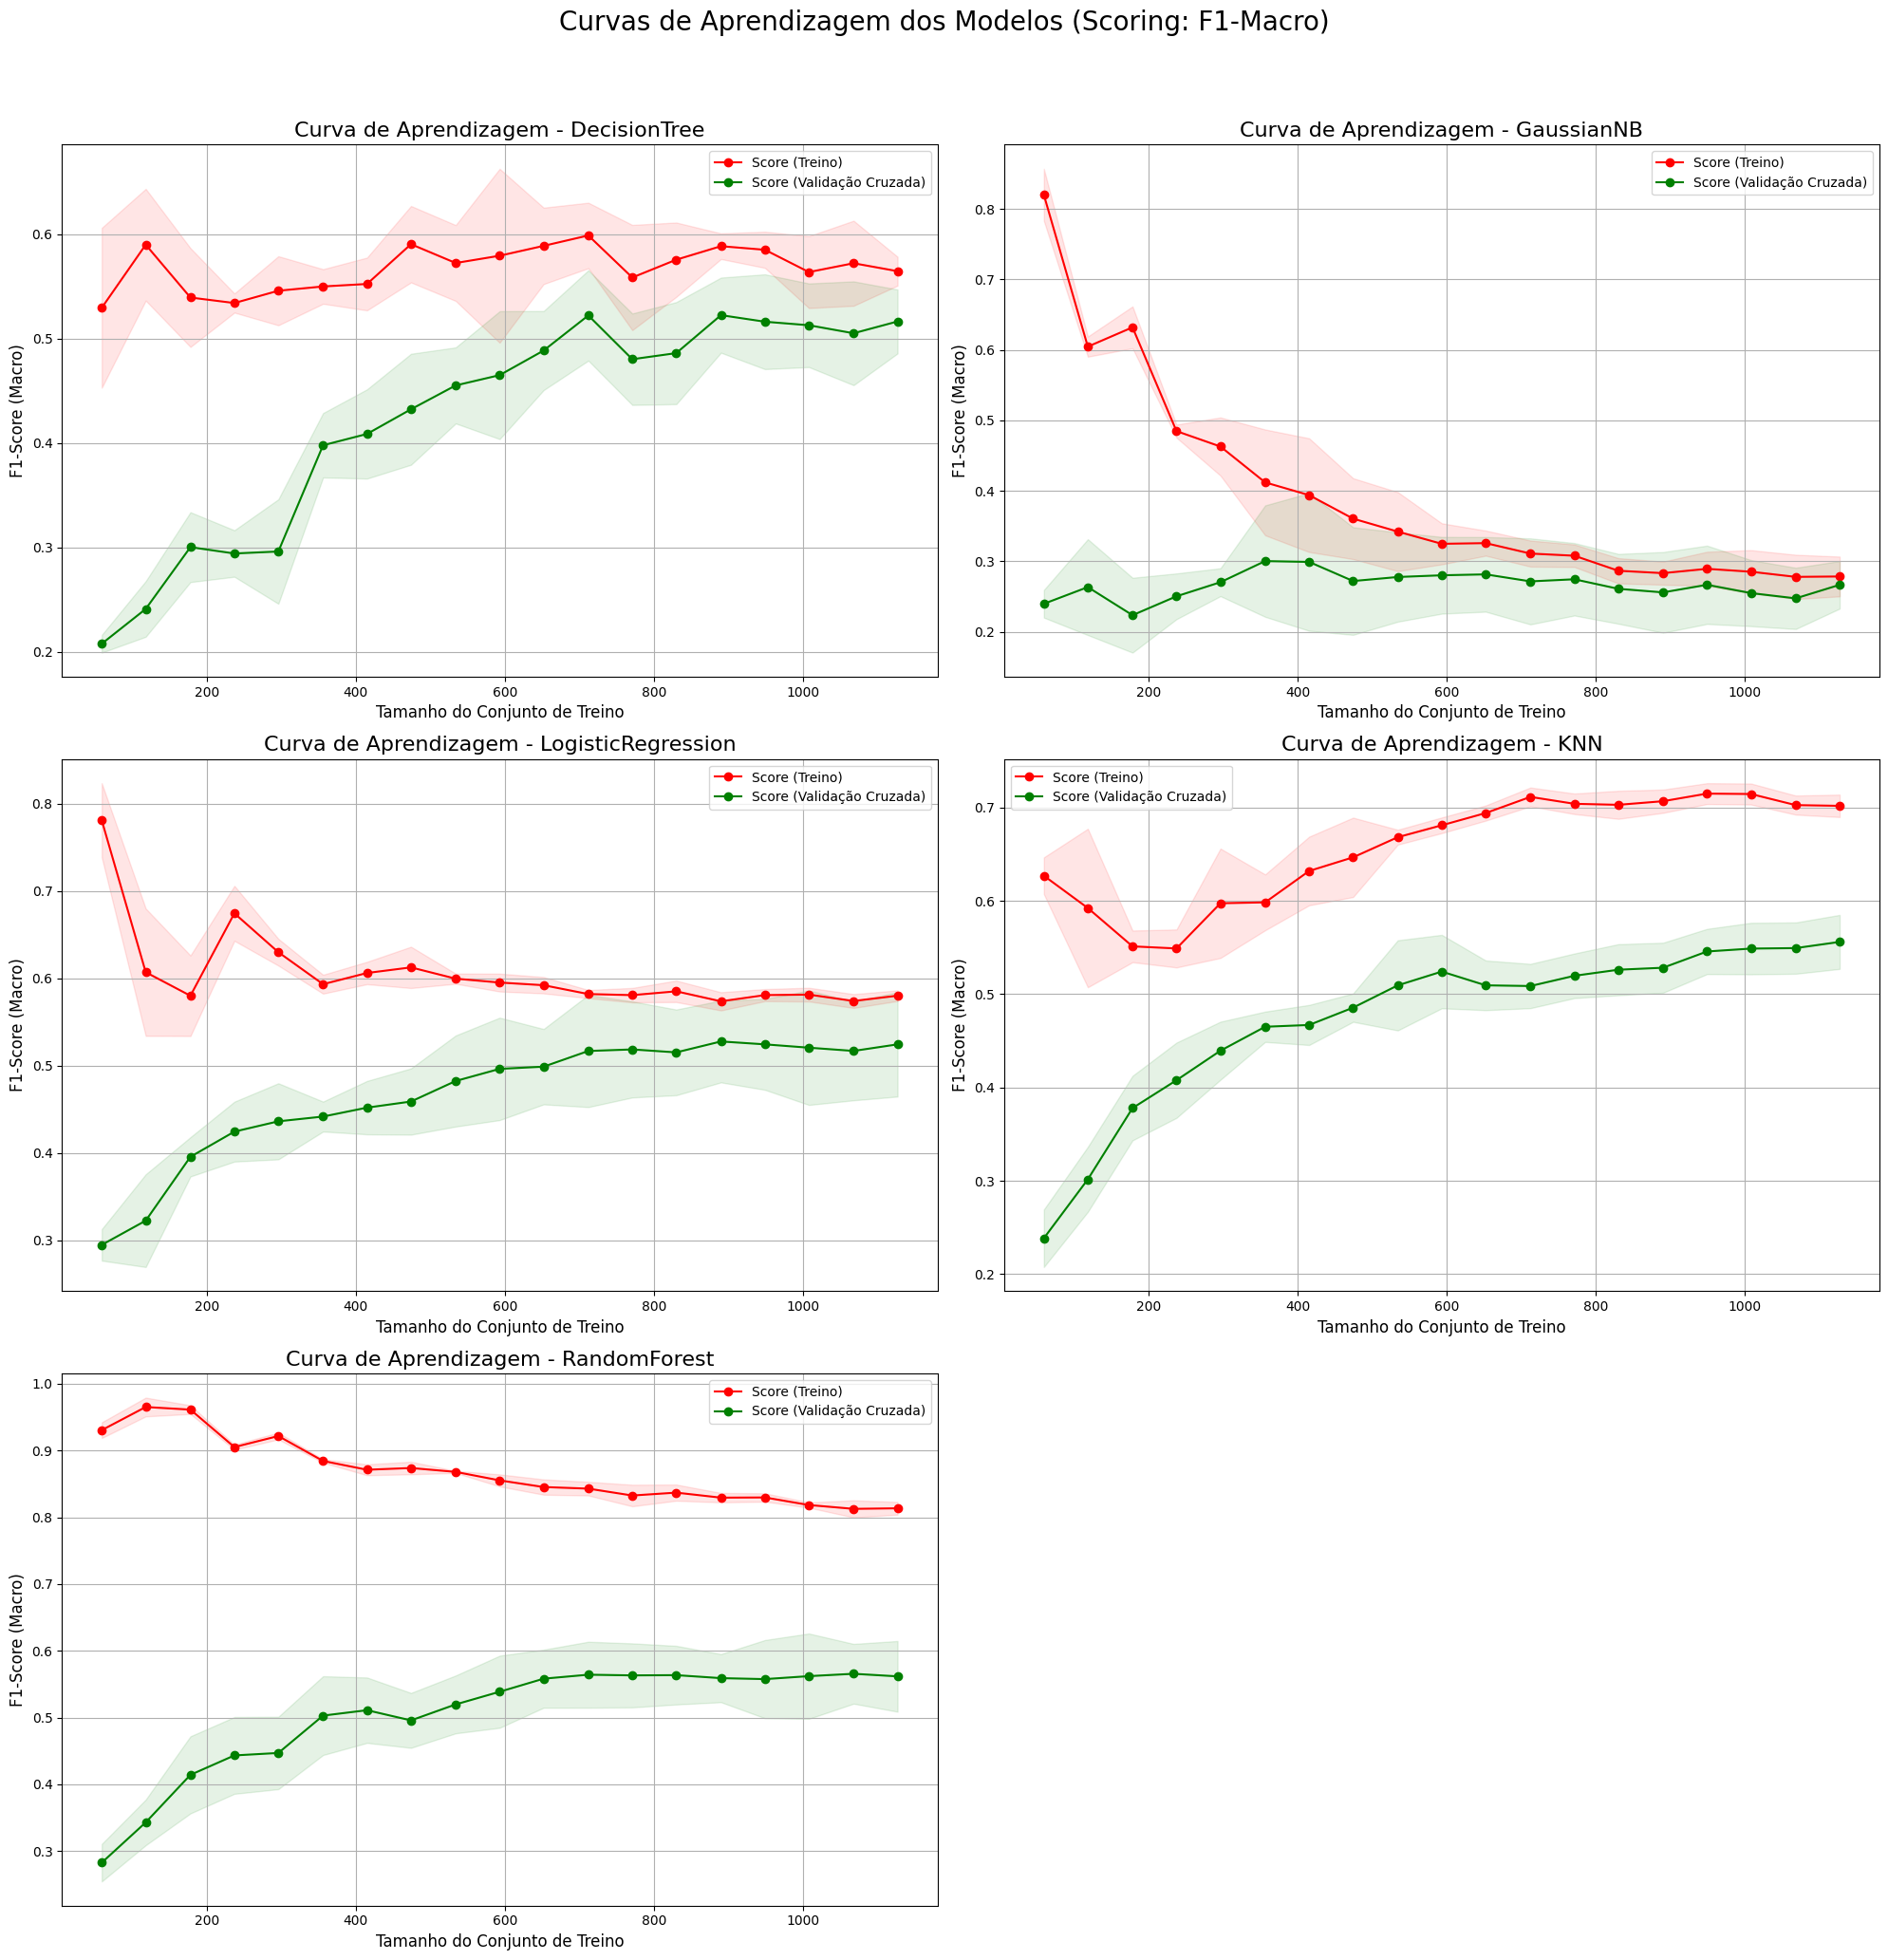


--- Curvas de Aprendizagem Geradas ---


In [ ]:

print("\n Geração das Curvas de Aprendizagem")

# Definindo os tamanhos do conjunto de treino (5% a 95% com passo de 5%)
train_sizes_abs = np.linspace(0.05, 0.95, 19)

# Preparando o X e y completos (Treino + Validação) para a validação cruzada
X_train_val = pd.concat([X_train_scaled, X_test_scaled])
y_train_val = pd.concat([y_train, y_test])

# Criando a figura do Matplotlib
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(20, 20))
fig.suptitle('Curvas de Aprendizagem dos Modelos (Scoring: F1-Macro)', fontsize=20, y=1.03)
axes = axes.flatten()

# Iterar sobre os 5 melhores modelos que salvamos
for i, (model_name, model) in enumerate(best_models.items()):

    print(f"Gerando curva de aprendizagem para: {model_name}...")

    # Gerando os dados da curva de aprendizagem
    train_sizes, train_scores, validation_scores = learning_curve(
        estimator=model,
        X=X_train_val,
        y=y_train_val,
        train_sizes=train_sizes_abs,
        cv=5, # Usando 5 folds de validação cruzada
        scoring='f1_macro', # Métrica principal
        n_jobs=-1,
        random_state=42
    )

    # Calculando as médias e desvios
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    validation_scores_mean = np.mean(validation_scores, axis=1)
    validation_scores_std = np.std(validation_scores, axis=1)

    # Plotando no subplot correspondente
    ax = axes[i]
    ax.set_title(f'Curva de Aprendizagem - {model_name}', fontsize=16)
    ax.set_xlabel('Tamanho do Conjunto de Treino', fontsize=12)
    ax.set_ylabel('F1-Score (Macro)', fontsize=12)

    # Plotando as áreas de desvio padrão
    ax.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1, color="r")
    ax.fill_between(train_sizes, validation_scores_mean - validation_scores_std,
                     validation_scores_mean + validation_scores_std, alpha=0.1, color="g")

    # Plotando as curvas de média
    ax.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Score (Treino)")
    ax.plot(train_sizes, validation_scores_mean, 'o-', color="g",
             label="Score (Validação Cruzada)")

    ax.legend(loc="best")
    ax.grid(True)

# Escondendo o último subplot (se tivermos 5 modelos)
if len(best_models) < 6:
    axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

print("\n--- Curvas de Aprendizagem Geradas ---")

### Curvas de Aprendizagem
A análise das curvas de aprendizagem evidenciou que modelos com maior complexidade paramétrica requerem volumes mais amplos de dados para alcançar estabilidade no desempenho. A convergência observada entre as curvas de treinamento e validação nos modelos de melhor desempenho indicou adequada capacidade de generalização, sugerindo que os algoritmos aprenderam efetivamente os padrões subjacentes aos dados sem significativo overfitting.

## Conclusão Geral
O estudo evidenciou a importância do pré-processamento e da escolha de modelos adequados em problemas com classes desbalanceadas. A Random Forest se destacou pelo melhor desempenho e estabilidade, enquanto modelos simples serviram como base comparativa. As etapas de pré-processamento demonstraram ser fundamentais para o adequado funcionamento de algoritmos sensíveis à escala, como o K-NN. A análise exploratória inicial identificou o desbalanceamento na distribuição das classes, fator que impactou significativamente o desempenho de todos os modelos testados.